# Detecting and Quantifying Airline Delay Cascades at Scale Using PySpark RDDs
**STA 473 – Tools and Techniques for Data Science** | Midterm stage (45%)
**Students:** Ahmad Fayyaz (SP24-BST-002) and Hajira Shahbaz (SP24-BST-010)

**Data:** 2015 Flight Delays and Cancellations (US Bureau of Transportation Statistics), about 5.8 million flights.

**How this notebook is organised**

| Part | What it does | Run it? |
|---|---|---|
| 0. Setup | Java, PySpark, Drive, Spark session | Always, first |
| 1. Data cleaning (munging) | Raw CSV to clean flights, saved as Parquet | Only to show or rebuild the cleaning (needs the raw zip) |
| 2. Cascade analysis | Chains of delay along one aircraft | Always |
| 3. Exploratory analysis | Delay by airport, carrier, month, hour, cause | Always |

## Part 0. Setup

In [1]:
# Java 17 (Spark needs it) and PySpark
!sudo apt-get -qq update && sudo apt-get -qq install -y openjdk-17-jdk-headless
!pip install -q pyspark==4.0.4 py4j==0.10.9.9 matplotlib

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
debconf: unable to initialize frontend: Dialog
debconf: (No usable dialog-like program is installed, so the dialog based frontend cannot be used. at /usr/share/perl5/Debconf/FrontEnd/Dialog.pm line 79, <STDIN> line 2.)
debconf: falling back to frontend: Readline
debconf: unable to initialize frontend: Readline
debconf: (This frontend requires a controlling tty.)
debconf: falling back to frontend: Teletype
dpkg-preconfigure: unable to re-open stdin: 
Selecting previously unselected package openjdk-17-jre-headless:amd64.
(Reading database ... 122813 files and directories currently installed.)
Preparing to unpack .../openjdk-17-jre-headless_17.0.21.0.3+1-1~24.04.1_amd64.deb ...
Unpacking openjdk-17-jre-headless:amd64 (17.0.21.0.3+1-1~24.04.1) ...
Selecting previously unselected package openjdk-17-jdk-he

In [4]:
from google.colab import drive
drive.mount('/content/drive')

# ---- paths: ----
ZIP_PATH     = '/content/drive/MyDrive/archive (1).zip'                   # raw data
PARQUET_PATH = '/content/drive/MyDrive/clean_flights_backup.parquet'      # cleaned data

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [3]:
from pyspark.sql import SparkSession

spark = (SparkSession.builder
         .appName("DelayCascades")
         .master("local[*]")
         .config("spark.driver.memory", "6g")
         .config("spark.sql.shuffle.partitions", "16")
         .getOrCreate())
sc = spark.sparkContext
print("Spark", spark.version)

Spark 4.0.4


## Part 1. Data cleaning (data munging) with RDDs
Goal: turn the raw BTS file (one text line per flight) into a clean RDD of `Flight` records.
Every step below uses RDD operations (`textFile`, `filter`, `flatMap`, `map`, `reduceByKey`), accumulators (counters) and a broadcast variable.

*Skip this whole part if only want to rerun the analysis. Part 2 reads the saved cleaned data.*

### 1.1 Unzip and read the raw file

In [ ]:
!mkdir -p /content/data
!unzip -q -o "$ZIP_PATH" -d /content/data
!ls -lh /content/data

In [ ]:
lines = sc.textFile("file:///content/data/flights.csv")     # one element per text line
header = lines.first()
print(header)
print()
for row in lines.take(3):
    print(row)
print("\nLines in file (including header):", lines.count())

### 1.2 Cleaning rules and helper functions
- Drop **malformed** rows (wrong number of columns or unreadable numbers).
- Drop **cancelled or diverted** flights (they never completed a leg).
- Drop rows with **no tail number** (cannot be placed on an aircraft).
- Convert times like `2354` into minutes, and put every flight on **one global clock** (`dep_abs`, `arr_abs`) so that gaps between flights can be computed.
- The arrival time is on the destination's local clock, so the **time-zone gap** is worked out from the data itself.
- Blank cause columns mean 0 minutes.

In [ ]:
from collections import namedtuple
import datetime
from operator import add

FIELDS = header.split(',')
assert len(FIELDS) == 31, f"unexpected column count: {len(FIELDS)}"
IDX = {name: i for i, name in enumerate(FIELDS)}      # column name -> position

Flight = namedtuple('Flight', [
    'year','month','day','airline','flight_no','tail','origin','dest',
    'sched_dep','sched_arr','dep_abs','arr_abs',
    'dep_delay','arr_delay','late_ac','weather','airline_delay','nas',
    'security','distance'])

def to_min(hhmm):                  # '0005' -> 5 ,  '2354' -> 1434
    v = int(hhmm)
    return (v // 100 % 24) * 60 + v % 100

def cause(x):                      # blank cause column = 0 minutes
    return int(float(x)) if x != '' else 0

### 1.3 The cleaning pass (`flatMap`)
`parse` returns `[]` to drop a row and `[Flight(...)]` to keep it. Accumulators count how many rows were dropped for each reason.

In [ ]:
# Accumulators: counters that workers add to and the driver reads
total              = sc.accumulator(0)
bad_rows           = sc.accumulator(0)
cancelled_diverted = sc.accumulator(0)
missing_tail       = sc.accumulator(0)

def parse(line):
    total.add(1)
    f = line.split(',')
    if len(f) != len(FIELDS):                                  # malformed row
        bad_rows.add(1); return []
    if f[IDX['CANCELLED']] == '1' or f[IDX['DIVERTED']] == '1':
        cancelled_diverted.add(1); return []
    tail = f[IDX['TAIL_NUMBER']].strip()
    if tail == '':                                             # cannot place on an aircraft
        missing_tail.add(1); return []
    try:
        year, month, day = int(f[IDX['YEAR']]), int(f[IDX['MONTH']]), int(f[IDX['DAY']])
        sd = to_min(f[IDX['SCHEDULED_DEPARTURE']])
        sa = to_min(f[IDX['SCHEDULED_ARRIVAL']])
        elapsed = int(float(f[IDX['SCHEDULED_TIME']]))         # scheduled flight minutes
        base = datetime.date(year, month, day).toordinal() * 1440
        dep_abs = base + sd                                    # departure on the global clock
        off = ((sa - sd - elapsed + 720) % 1440) - 720         # time-zone gap, worked out from the data
        arr_abs = dep_abs + elapsed + off                      # arrival on the destination's local clock
        return [Flight(year, month, day, f[IDX['AIRLINE']], f[IDX['FLIGHT_NUMBER']],
                       tail, f[IDX['ORIGIN_AIRPORT']], f[IDX['DESTINATION_AIRPORT']],
                       sd, sa, dep_abs, arr_abs,
                       int(float(f[IDX['DEPARTURE_DELAY']])),
                       int(float(f[IDX['ARRIVAL_DELAY']])),
                       cause(f[IDX['LATE_AIRCRAFT_DELAY']]),
                       cause(f[IDX['WEATHER_DELAY']]),
                       cause(f[IDX['AIRLINE_DELAY']]),
                       cause(f[IDX['AIR_SYSTEM_DELAY']]),
                       cause(f[IDX['SECURITY_DELAY']]),
                       int(float(f[IDX['DISTANCE']])))]
    except ValueError:                                         # unreadable number or time
        bad_rows.add(1); return []

parsed = lines.filter(lambda l: l != header).flatMap(parse).cache()
n_parsed = parsed.count()          # one action runs the whole pass

print("Rows read:               ", total.value)
print("Malformed / unparseable: ", bad_rows.value)
print("Cancelled or diverted:   ", cancelled_diverted.value)
print("Missing tail number:     ", missing_tail.value)
print("Parsed (before dedupe):  ", n_parsed)

### 1.4 Removing duplicates (broadcast variable)
One aircraft cannot depart twice at the same minute, so such rows are duplicates or errors. The small set of repeated keys is found with `reduceByKey`, **broadcast** to all workers, and every row that matches is dropped.

In [ ]:
dup_keys = set(parsed.map(lambda r: ((r.tail, r.dep_abs), 1))
                     .reduceByKey(add)
                     .filter(lambda kv: kv[1] > 1)
                     .keys().collect())
bc_dups = sc.broadcast(dup_keys)                      # shipped once to every worker

flights = parsed.filter(lambda r: (r.tail, r.dep_abs) not in bc_dups.value).cache()
kept = flights.count()

print("Duplicate-key rows removed:", n_parsed - kept)
print("Kept (clean flights):      ", kept)
for r in flights.take(2):
    print(r)

### 1.5 Quality checks on the cleaned data

In [ ]:
# (a) airport codes that are not 3 letters (October 2015 uses numeric airport IDs)
odd = flights.filter(lambda r: len(r.origin) != 3 or len(r.dest) != 3).cache()
print("Rows with a numeric airport ID:", odd.count(), "(flagged and kept)")
print("By month:", sorted(odd.map(lambda r: (r.month, 1)).reduceByKey(add).collect()))
print("Sample values:", odd.map(lambda r: r.origin).distinct().take(5))

In [ ]:
# (b) other sanity checks
dups_left = (flights.map(lambda r: ((r.tail, r.dep_abs), 1))
                    .reduceByKey(add).filter(lambda kv: kv[1] > 1).count())
print("Duplicates left (should be 0):                  ", dups_left)
print("Arrival not after departure (local clocks):     ",
      flights.filter(lambda r: r.arr_abs <= r.dep_abs).count(), "(kept)")
print("Arrival delay over 1000 min:                    ",
      flights.filter(lambda r: r.arr_delay > 1000).count())
print("Arrival delay under -60 min (very early):       ",
      flights.filter(lambda r: r.arr_delay < -60).count())
print("Late-aircraft delay > 0 but arrival delay < 15: ",
      flights.filter(lambda r: r.late_ac > 0 and r.arr_delay < 15).count())

In [ ]:
# (c) are the time-zone gaps plausible? (US zones differ by at most about 6 hours)
def implied_gap(line):
    f = line.split(',')
    try:
        sd = to_min(f[IDX['SCHEDULED_DEPARTURE']]); sa = to_min(f[IDX['SCHEDULED_ARRIVAL']])
        el = int(float(f[IDX['SCHEDULED_TIME']]))
        return [((sa - sd - el + 720) % 1440) - 720]
    except Exception:
        return []

gaps = lines.filter(lambda l: l != header).flatMap(implied_gap).cache()
print("Flights checked:", gaps.count())
print("Gap within -360..+360 min (plausible):", gaps.filter(lambda g: -360 <= g <= 360).count())
print("Gap outside that range (suspicious):  ", gaps.filter(lambda g: g < -360 or g > 360).count())

### 1.6 Save the cleaned data
Parquet is a folder of part files, so it will not open like a normal file in Drive. Parts 2 and 3 read it back. The cell below is switched off by default so it cannot overwrite good data by accident. Set `SAVE = True` only when rebuilding.

In [ ]:
SAVE = False        # <- change to True only when you really want to rebuild the saved file

if SAVE:
    df = spark.createDataFrame(flights.map(tuple), schema=list(Flight._fields))
    df.write.mode('overwrite').parquet(PARQUET_PATH)
    print("saved to", PARQUET_PATH)
else:
    print("SAVE is False: nothing written.")

## Part 2. Delay cascade analysis
**Idea:** an aircraft flies a sequence of flights. If it lands late and the next flight (same aircraft, same airport) leaves late because of it, the delay was *passed on*. A run of such links is a **cascade chain**.

**A link from flight *a* to the next flight *b* of the same aircraft exists when:**
- `a` arrived at least `T` = 15 minutes late,
- the planned time on the ground (`slack`) is at most `S` = 60 minutes,
- `b` left late, and BTS records a late-aircraft delay for `b`,
- some delay really carried over: `inherited = min(max(0, a.arr_delay - slack), b.dep_delay) > 0`.

**Cascade Impact Score** of a chain = total inherited minutes along the chain.

In [6]:
# Load the cleaned data
df = spark.read.parquet(PARQUET_PATH)

T = 15     # a flight must land at least 15 min late to pass delay on
S = 60     # the planned turnaround must be at most 60 min (45 / 60 / 90 are tested later)

flights = (df.rdd
             .filter(lambda r: r.month <= 2)      # starting with January and February only
             .cache())
print("Flights in slice:", flights.count())

Flights in slice: 864516


### 2.1 Pair and chain logic

In [8]:
from collections import namedtuple

Pair = namedtuple('Pair', ['tail','prev_no','next_no','airport','prev_origin','next_dest',
                           'prev_dep_abs','slack','prev_arr_delay','next_dep_delay',
                           'next_late_ac','inherited','is_link','month','airline'])

def make_pairs(item, T=T, S=S):
    tail, flights = item
    fl = sorted(flights, key=lambda r: r.dep_abs)          # the aircraft's flights in time order
    out = []
    for a, b in zip(fl, fl[1:]):                           # every consecutive pair (a, b)
        if a.dest != b.origin:                             # a gap (e.g. a cancelled leg): not linked
            continue
        slack = b.dep_abs - a.arr_abs                      # planned minutes on the ground
        if slack < 0:
            continue
        # delay that really carries over: what is left after the slack absorbs part of it,
        # and never more than the next flight's own departure delay
        inherited = min(max(0, a.arr_delay - slack), b.dep_delay)
        is_link = (a.arr_delay >= T and slack <= S
                   and b.dep_delay > 0 and b.late_ac > 0
                   and inherited > 0)
        if not is_link:
            inherited = 0
        out.append(Pair(tail, a.flight_no, b.flight_no, a.dest, a.origin, b.dest,
                        a.dep_abs, slack, a.arr_delay, b.dep_delay, b.late_ac,
                        inherited, is_link, a.month, a.airline))
    return out

def make_chains(item, T=T, S=S):
    tail, flights = item
    pairs = make_pairs(item, T, S)
    fl = sorted(flights, key=lambda r: r.dep_abs)
    pos = {(r.flight_no, r.dep_abs): i for i, r in enumerate(fl)}
    link_from = {(p.prev_no, p.prev_dep_abs): p for p in pairs if p.is_link}
    targets = set()
    for key in link_from:
        j = pos[key] + 1
        targets.add((fl[j].flight_no, fl[j].dep_abs))
    chains = []
    for r in fl:
        key = (r.flight_no, r.dep_abs)
        if key in link_from and key not in targets:        # a ROOT: passes delay on, inherited none
            total, length, cur, path = 0, 1, key, [r.flight_no]
            while cur in link_from:                        # walk down the chain
                p = link_from[cur]
                total += p.inherited
                length += 1
                j = pos[cur] + 1
                cur = (fl[j].flight_no, fl[j].dep_abs)
                path.append(fl[j].flight_no)
            amp = round(total / r.arr_delay, 2) if r.arr_delay > 0 else 0.0
            chains.append((tail, r.flight_no, r.origin, r.dest, r.month, r.airline,
                           r.arr_delay, length, total, amp, tuple(path)))
    return chains

### 2.2 Build pairs and chains (`groupByKey` on tail number)

In [9]:
by_aircraft = (flights
               .map(lambda r: (r.tail, r))     # key = tail number
               .groupByKey()                   # all flights of one plane together
               .cache())

pairs  = by_aircraft.flatMap(make_pairs).cache()
chains = by_aircraft.flatMap(make_chains).cache()

n_pairs  = pairs.count()
n_links  = pairs.filter(lambda p: p.is_link).count()
n_chains = chains.count()
print("Consecutive pairs:", n_pairs)
print("Propagation links:", n_links, f"({n_links/n_pairs:.1%})")
print("Chains (roots)   :", n_chains)

Consecutive pairs: 839235
Propagation links: 37143 (4.4%)
Chains (roots)   : 24349


### 2.3 Results: top chains, chain lengths, airports that pass on the most delay

In [10]:
print("Top 5 chains by Cascade Impact Score (total inherited minutes):")
for c in chains.takeOrdered(5, key=lambda c: -c[8]):
    print(f"tail {c[0]} | root flight {c[1]} {c[2]}->{c[3]} | arrived {c[6]} min late | "
          f"chain length {c[7]} | inherited {c[8]} min | amplification {c[9]} | path {c[10]}")

print("\nChain length distribution:")
print(sorted(chains.map(lambda c: (c[7], 1)).reduceByKey(lambda a, b: a + b).collect()))

print("\nAirports where most delay is passed on (inherited minutes):")
print(pairs.filter(lambda p: p.is_link)
           .map(lambda p: (p.airport, p.inherited))
           .reduceByKey(lambda a, b: a + b)
           .takeOrdered(10, key=lambda kv: -kv[1]))

Top 5 chains by Cascade Impact Score (total inherited minutes):
tail N928FR | root flight 1279 PHL->MCO | arrived 321 min late | chain length 5 | inherited 1304 min | amplification 4.06 | path ('1279', '1278', '1281', '1280', '1277')
tail N210FR | root flight 1256 ORD->MIA | arrived 686 min late | chain length 3 | inherited 1275 min | amplification 1.86 | path ('1256', '1257', '1067')
tail N910AT | root flight 2673 BOS->LGA | arrived 130 min late | chain length 6 | inherited 944 min | amplification 7.26 | path ('2673', '2678', '2681', '2686', '793', '2571')
tail N755EV | root flight 4950 MSP->MDW | arrived 205 min late | chain length 7 | inherited 937 min | amplification 4.57 | path ('4950', '4950', '5324', '5324', '5028', '5028', '5287')
tail N941FR | root flight 1046 MCO->MDT | arrived 333 min late | chain length 4 | inherited 928 min | amplification 2.79 | path ('1046', '1047', '1013', '1012')

Chain length distribution:
[(2, 16498), (3, 4617), (4, 2033), (5, 808), (6, 295), (7, 81)

### 2.4 Three example chains, shown leg by leg

In [11]:
import datetime

def clock(abs_min):
    """global-clock minute -> 'Jan 05 14:35' (local time at that airport)"""
    d = datetime.date.fromordinal(abs_min // 1440)
    m = abs_min % 1440
    return f"{d.strftime('%b %d')} {m // 60:02d}:{m % 60:02d}"

def chain_legs(c, tail_flights):
    """Find the chain's flights inside one aircraft's sorted flight list."""
    fl = sorted(tail_flights, key=lambda r: r.dep_abs)
    path = list(c[10])
    for i in range(len(fl) - len(path) + 1):
        window = fl[i:i + len(path)]
        if [r.flight_no for r in window] == path and window[0].arr_delay == c[6]:
            return window
    return []

def show_chain(c, tail_flights, T=T, S=S):
    legs = chain_legs(c, tail_flights)
    print("=" * 100)
    print(f"Aircraft {c[0]} | airline {c[5]} | root flight {c[1]} {c[2]}->{c[3]} | "
          f"chain length {c[7]} | Cascade Impact Score {c[8]} min | amplification {c[9]}")
    print("-" * 100)
    print(f"{'leg':<4}{'flight':<8}{'route':<10}{'sched dep':<14}{'sched arr':<14}"
          f"{'dep delay':>10}{'arr delay':>10}{'slack to next':>15}{'inherited':>11}")
    for i, r in enumerate(legs):
        if i + 1 < len(legs):
            nxt = legs[i + 1]
            slack = nxt.dep_abs - r.arr_abs
            inh = min(max(0, r.arr_delay - slack), nxt.dep_delay)
            slack_s, inh_s = f"{slack} min", f"{inh} min"
        else:
            slack_s, inh_s = "-", "-"
        tag = "  <- ROOT" if i == 0 else ""
        print(f"{i+1:<4}{r.flight_no:<8}{r.origin+'->'+r.dest:<10}{clock(r.dep_abs):<14}"
              f"{clock(r.arr_abs):<14}{r.dep_delay:>10}{r.arr_delay:>10}{slack_s:>15}{inh_s:>11}{tag}")
    print()

def pick_and_show(c):
    tail_flights = flights.filter(lambda r: r.tail == c[0]).collect()   # one aircraft only
    show_chain(c, tail_flights)

top   = chains.takeOrdered(1, key=lambda c: -c[8])[0]                        # highest score
mid   = chains.filter(lambda c: c[7] == 4).takeSample(False, 1, seed=7)[0]   # a typical chain (length 4)
short = chains.filter(lambda c: c[7] == 2).takeSample(False, 1, seed=7)[0]   # most common kind (one link)

for c in (top, mid, short):
    pick_and_show(c)

Aircraft N928FR | airline F9 | root flight 1279 PHL->MCO | chain length 5 | Cascade Impact Score 1304 min | amplification 4.06
----------------------------------------------------------------------------------------------------
leg flight  route     sched dep     sched arr      dep delay arr delay  slack to next  inherited
1   1279    PHL->MCO  Jan 07 05:30  Jan 07 08:10         301       321         40 min    281 min  <- ROOT
2   1278    MCO->PHL  Jan 07 08:50  Jan 07 11:10         321       337         40 min    297 min
3   1281    PHL->TPA  Jan 07 11:50  Jan 07 14:25         372       406         40 min    366 min
4   1280    TPA->PHL  Jan 07 15:05  Jan 07 17:30         409       400         40 min    360 min
5   1277    PHL->MCO  Jan 07 18:10  Jan 07 20:50         394       477              -          -

Aircraft N8923A | airline OO | root flight 4550 MSP->CMH | chain length 4 | Cascade Impact Score 204 min | amplification 2.04
------------------------------------------------------

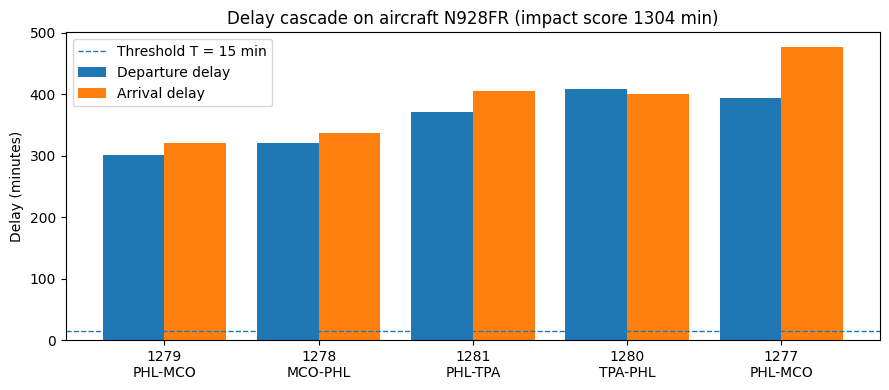

In [12]:
import matplotlib.pyplot as plt

def plot_chain(c):
    tail_flights = flights.filter(lambda r: r.tail == c[0]).collect()
    legs = chain_legs(c, tail_flights)
    labels = [f"{r.flight_no}\n{r.origin}-{r.dest}" for r in legs]
    x = range(len(legs))
    plt.figure(figsize=(9, 4))
    plt.bar([i - 0.2 for i in x], [r.dep_delay for r in legs], width=0.4, label="Departure delay")
    plt.bar([i + 0.2 for i in x], [r.arr_delay for r in legs], width=0.4, label="Arrival delay")
    plt.axhline(T, linestyle="--", linewidth=1, label=f"Threshold T = {T} min")
    plt.xticks(list(x), labels)
    plt.ylabel("Delay (minutes)")
    plt.title(f"Delay cascade on aircraft {c[0]} (impact score {c[8]} min)")
    plt.legend()
    plt.tight_layout()
    plt.show()

plot_chain(top)

## Part 3. Exploratory analysis on the full year
Average arrival delay by airport, carrier, month and hour, plus the share of delay minutes by cause. Computed with `aggregateByKey` and `reduceByKey` on the whole 5.7 million rows.

In [13]:
from pyspark import StorageLevel

cols = ['origin','airline','month','sched_dep','arr_delay',
        'late_ac','airline_delay','nas','weather','security']      # only what we need: saves memory

full = (spark.read.parquet(PARQUET_PATH)
             .select(*cols)
             .rdd
             .persist(StorageLevel.MEMORY_AND_DISK))               # spill to disk instead of crashing
print("Flights:", full.count())

Flights: 5712814


In [14]:
def avg_delay_by(rdd, key_fn, min_flights=1):
    """(key, (sum of arrival delay, number of flights)) -> (key, average, flights)"""
    sums = (rdd.map(lambda r: (key_fn(r), r.arr_delay))
               .aggregateByKey((0, 0),
                               lambda acc, v: (acc[0] + v, acc[1] + 1),     # within a partition
                               lambda a, b: (a[0] + b[0], a[1] + b[1])))    # across partitions
    return (sums.filter(lambda kv: kv[1][1] >= min_flights)
                .map(lambda kv: (kv[0], kv[1][0] / kv[1][1], kv[1][1])))

# Airports: skip the October rows whose airport is a 5-digit number (not a 3-letter code)
known = full.filter(lambda r: len(r.origin) == 3)

by_airport = avg_delay_by(known, lambda r: r.origin, min_flights=10000)
print("Highest average arrival delay by origin airport (10,000+ flights):")
for k, avg, n in by_airport.takeOrdered(10, key=lambda t: -t[1]):
    print(f"  {k}: {avg:6.2f} min  ({n:,} flights)")

by_carrier = avg_delay_by(full, lambda r: r.airline)
print("\nAverage arrival delay by carrier:")
for k, avg, n in by_carrier.takeOrdered(20, key=lambda t: -t[1]):
    print(f"  {k}: {avg:6.2f} min  ({n:,} flights)")

by_month = sorted(avg_delay_by(full, lambda r: r.month).collect())
print("\nAverage arrival delay by month:")
for k, avg, n in by_month:
    print(f"  month {k:>2}: {avg:6.2f} min  ({n:,} flights)")

by_hour = sorted(avg_delay_by(full, lambda r: r.sched_dep // 60).collect())
print("\nAverage arrival delay by scheduled departure hour:")
for k, avg, n in by_hour:
    print(f"  hour {k:>2}: {avg:6.2f} min  ({n:,} flights)")

Highest average arrival delay by origin airport (10,000+ flights):
  ORD:   8.58 min  (276,494 flights)
  DAL:   7.95 min  (58,650 flights)
  PBI:   7.94 min  (22,132 flights)
  HOU:   7.54 min  (51,102 flights)
  IAH:   7.37 min  (144,012 flights)
  BWI:   7.22 min  (84,302 flights)
  DEN:   7.18 min  (193,364 flights)
  MIA:   7.02 min  (68,296 flights)
  MCO:   6.95 min  (109,514 flights)
  DFW:   6.90 min  (232,611 flights)

Average arrival delay by carrier:
  NK:  14.47 min  (115,187 flights)
  F9:  12.48 min  (90,072 flights)
  B6:   6.67 min  (262,034 flights)
  EV:   6.57 min  (554,672 flights)
  MQ:   6.45 min  (278,755 flights)
  OO:   5.83 min  (576,674 flights)
  UA:   5.42 min  (507,680 flights)
  VX:   4.73 min  (61,240 flights)
  WN:   4.35 min  (1,241,951 flights)
  US:   3.69 min  (194,195 flights)
  AA:   3.43 min  (712,827 flights)
  HA:   2.02 min  (76,039 flights)
  DL:   0.17 min  (870,061 flights)
  AS:  -0.98 min  (171,427 flights)

Average arrival delay by mont

### Share of delay minutes by cause

In [15]:
# In the BTS data the five cause columns are filled only for flights that arrived 15+ minutes late.
delayed = full.filter(lambda r: r.arr_delay >= 15)
n_delayed = delayed.count()

cause_totals = (delayed
    .flatMap(lambda r: [("Late aircraft", r.late_ac), ("Airline", r.airline_delay),
                        ("Air system (NAS)", r.nas), ("Weather", r.weather),
                        ("Security", r.security)])
    .reduceByKey(lambda a, b: a + b)
    .collect())

grand = sum(v for _, v in cause_totals)
print(f"Flights arriving 15+ min late: {n_delayed:,}")
print("\nShare of recorded delay minutes by cause:")
for k, v in sorted(cause_totals, key=lambda kv: -kv[1]):
    print(f"  {k:<18}{v:>12,} min   {v / grand:6.1%}")

Flights arriving 15+ min late: 1,062,804

Share of recorded delay minutes by cause:
  Late aircraft       24,926,341 min    39.8%
  Airline             20,123,433 min    32.2%
  Air system (NAS)    14,330,316 min    22.9%
  Weather              3,097,537 min     5.0%
  Security                80,974 min     0.1%


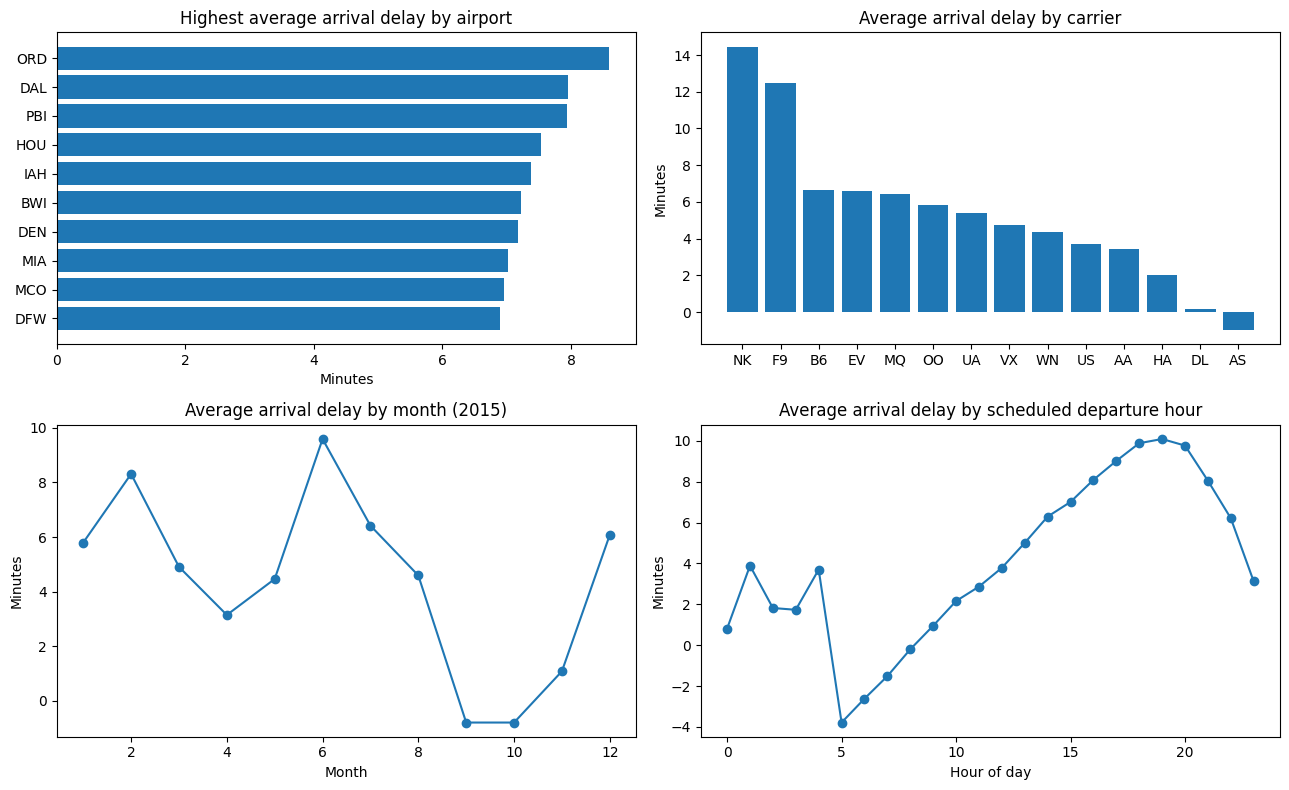

In [16]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(2, 2, figsize=(13, 8))

top_air = by_airport.takeOrdered(10, key=lambda t: -t[1])
ax[0][0].barh([k for k, _, _ in top_air][::-1], [a for _, a, _ in top_air][::-1])
ax[0][0].set_title("Highest average arrival delay by airport")
ax[0][0].set_xlabel("Minutes")

carr = by_carrier.takeOrdered(20, key=lambda t: -t[1])
ax[0][1].bar([k for k, _, _ in carr], [a for _, a, _ in carr])
ax[0][1].set_title("Average arrival delay by carrier")
ax[0][1].set_ylabel("Minutes")

ax[1][0].plot([k for k, _, _ in by_month], [a for _, a, _ in by_month], marker="o")
ax[1][0].set_title("Average arrival delay by month (2015)")
ax[1][0].set_xlabel("Month"); ax[1][0].set_ylabel("Minutes")

ax[1][1].plot([k for k, _, _ in by_hour], [a for _, a, _ in by_hour], marker="o")
ax[1][1].set_title("Average arrival delay by scheduled departure hour")
ax[1][1].set_xlabel("Hour of day"); ax[1][1].set_ylabel("Minutes")

plt.tight_layout()
plt.show()